# ЛР 3 — LLM на задачах машинного обучения
**Одна тетрадь: API → ответы → анализ.** Уже полученные ответы загружаются из `data/responses.jsonl`.
GigaChat-3-Ultra и GPT-6.1 Sol работают через API. **Qwen3-4B-Instruct-2507 запускалась в Google Colab на T4; её 36 реальных ответов уже сохранены.** Запуск весов здесь не требуется.

Выполни тетрадь сверху вниз: по умолчанию она анализирует готовые ответы. Для новых запросов включи нужный флаг ниже. Итоговая таблица — **answers.csv**; все графики остаются в тетради.

In [1]:
# Установка при первом запуске (сними комментарий):
# %pip install -q openai==3.26.1 gigachat==0.2.3 numpy==2.3.5 pandas==2.2.3 matplotlib==3.11.2 scipy==1.18.1 statsmodels==0.15.0 scikit-learn==1.9.1

import hashlib, itertools, json, os, re, sys, time, tempfile, subprocess
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.contingency_tables import mcnemar

DATA = Path.cwd() / 'data'
LOG = DATA / 'responses.jsonl'
config = json.loads((DATA / 'experiment.json').read_text())
questions = pd.read_csv(DATA / 'questions.csv', dtype=str).fillna('').set_index('id')
MODELS = ['gigachat', 'gpt', 'local']
SYSTEM, FORMATS = config['system'], config['formats']
RUN_GIGACHAT = False  # для запуска из РФ
RUN_GPT = False       # для запуска с доступом к зарубежному API
RUN_EXTRA = False     # дополнительно: 150 строк × 0/5/20-shot и 18 контрольных задач
RECHECK_CODE = False  # повторно исполнить исходные программы D

def read_records():
    return [json.loads(s) for s in LOG.read_text().splitlines()]

def save(table, path):
    flat = table.map(lambda v: v.replace('\r\n', '\n').replace('\r', '\n').replace('\n', r'\n') if isinstance(v, str) else v)
    flat.to_csv(path, index=False, encoding='utf-8-sig')

## Запросы к API
Ключи берутся из `.env` или вводятся скрыто при первом запросе. GigaChat и GPT запускаются раздельно; готовые полные ответы пропускаются. Сетевые ошибки сохраняются отдельно от ошибок решения.

In [2]:
API = {
    'gigachat': ('GigaChat-3-Ultra', 'https://api.giga.chat/v1', 'GIGACHAT_CREDENTIALS'),
    'gpt': ('gpt-6.1-sol', 'https://api.llm-gate.tech/v1', 'LLM_GATE_API_KEY'),
}
clients = {}

def ask(name, prompt, **task):
    model_id, url, key_name = API[name]
    payload = {'model': model_id, 'messages': [{'role': 'system', 'content': SYSTEM}, {'role': 'user', 'content': prompt}]}
    payload.update({'temperature': .0001, 'max_tokens': 4096} if name == 'gigachat'
                   else {'reasoning_effort': 'low', 'max_completion_tokens': 4096})
    record = {k: v for k, v in task.items() if k not in ['prompt', 'gold']}
    record.update(model=name, model_id=model_id, id=task.get('id', 'prompt'), stage=task.get('stage', 'free'),
                  prompt_hash=hashlib.sha256(prompt.encode()).hexdigest(),
                  date=datetime.now(timezone.utc).isoformat(), request=payload)
    started = time.perf_counter()
    try:
        if name not in clients:
            env = Path('.env')
            keys = dict(line.split('=', 1) for line in env.read_text().splitlines() if '=' in line and not line.lstrip().startswith('#')) if env.exists() else {}
            key = os.getenv(key_name) or keys.get(key_name, '').strip().strip('\"\'') or getpass(f'Ключ {name}: ')
            if name == 'gigachat':
                from gigachat import GigaChat
                clients[name] = GigaChat(credentials=key, base_url=url, scope='GIGACHAT_API_PERS',
                                         ca_bundle_file=str(DATA / 'russian_root.pem'), timeout=45, max_retries=0)
            else:
                from openai import OpenAI
                clients[name] = OpenAI(api_key=key, base_url=url, timeout=60, max_retries=1)
        response = clients[name].chat(payload) if name == 'gigachat' else clients[name].chat.completions.create(**payload)
        choice, usage = response.choices[0], response.usage
        record.update(answer=choice.message.content or '', finish_reason=choice.finish_reason,
                      prompt_tokens=usage.prompt_tokens, completion_tokens=usage.completion_tokens, tokens=usage.total_tokens)
        if not record['answer'] or record['finish_reason'] == 'length':
            raise ValueError('Нет полного ответа: увеличь лимит для этого запроса.')
    except (Exception, KeyboardInterrupt) as error:
        record['error'] = str(error) or 'Выполнение прервано'
        raise
    finally:
        record['seconds'] = round(time.perf_counter() - started, 3)
        with LOG.open('a', encoding='utf-8') as file:
            file.write(json.dumps(record, ensure_ascii=False) + '\n')
    return record['answer']

# Пример своего запроса:
# print(ask('gpt', 'Чем precision отличается от recall?'))

In [3]:
bank = [{'id': qid, 'тип': row['тип'], 'stage': 'bank', 'prompt': FORMATS[row['тип']] + '\n\n' + row['текст_ru']}
        for qid, row in questions.iterrows()]
support, test = pd.DataFrame(config['support']), pd.DataFrame(config['test'])
features = support.columns.drop(['row_id', 'target', 'in_5_shot'])
extra = list(config['hypothesis_tasks'])
for shots in [0, 5, 20]:
    examples = support.iloc[:0] if shots == 0 else support.loc[support.in_5_shot.eq(1)] if shots == 5 else support
    prefix = 'Классифицируй строку load_breast_cancer по пяти признакам. Классы: 0=malignant, 1=benign. Верни только 0 или 1, без пояснений.\n'
    if shots:
        prefix += 'Размеченные примеры:\n' + '\n'.join(', '.join(f'{c}={r[c]}' for c in features) + f' -> {int(r.target)}' for _, r in examples.iterrows()) + '\n'
    for _, row in test.iterrows():
        prompt = prefix + 'Новая строка: ' + ', '.join(f'{c}={row[c]}' for c in features) + '\nКласс:'
        extra.append({'id': f'E_{shots}_{int(row.row_id)}', 'stage': 'classification', 'тип': 'E',
                      'shots': shots, 'row_id': int(row.row_id), 'prompt': prompt})

def run(name):
    records = read_records()
    done = {(r['model'], r['id'], r.get('prompt_hash', hashlib.sha256(r['request']['messages'][-1]['content'].encode()).hexdigest()))
            for r in records if r.get('answer') and not r.get('error') and r.get('finish_reason') != 'length'}
    done_bank = {(r['model'], r['id']) for r in records if r.get('stage') == 'bank' and r.get('id') in questions.index
                 and r.get('answer') and not r.get('error') and r.get('finish_reason') != 'length'
                 and questions.loc[r['id'], 'текст_ru'] in r['request']['messages'][-1]['content']}
    spent = .20 + sum((r.get('prompt_tokens', 0) * 2 + r.get('completion_tokens', 0) * 10) / 1e6
                      for r in records if r['model'] == 'gpt' and r.get('prompt_tokens') is not None and r.get('completion_tokens') is not None)
    for task in bank + (extra if RUN_EXTRA else []):
        fingerprint = hashlib.sha256(task['prompt'].encode()).hexdigest()
        if (name, task['id'], fingerprint) in done or (task['stage'] == 'bank' and (name, task['id']) in done_bank):
            continue
        bound = (2 * (len((SYSTEM + task['prompt']).encode()) + 512) + 10 * 4096) / 1e6
        if name == 'gpt' and spent + bound > 1.80:
            print('Остановлено: бюджет $1.80 с резервом $0.20.'); break
        try:
            ask(name, **task)
            print(task['id'], name, 'готово')
        except Exception as error:
            print(task['id'], name, str(error)[:180])
        if name == 'gpt':
            r = read_records()[-1]
            spent += (r.get('prompt_tokens', 0) * 2 + r.get('completion_tokens', 0) * 10) / 1e6

**GigaChat: запуск из РФ.**

In [4]:
if RUN_GIGACHAT:
    run('gigachat')

**GPT: запуск с доступом к зарубежному API.**

In [5]:
if RUN_GPT:
    run('gpt')

## Оценка готовых ответов
A/B/E проверяются автоматически: числовой допуск — 1%, для B отдельно оценивается обоснование. Листы `data/review_1.csv` и `data/review_2.csv` скрывают названия моделей. Первый пока заполнен ИИ (`ai_preliminary`), второй — для независимого проверяющего. Каппа двух людей по разметке ИИ не вычисляется.

In [6]:
records = read_records()
selected = {}
for r in records:
    key = (r.get('id'), r.get('model'))
    if r.get('stage') != 'bank' or key[0] not in questions.index or key[1] not in MODELS:
        continue
    if questions.loc[key[0], 'текст_ru'] not in r['request']['messages'][-1]['content']:
        continue
    previous = selected.get(key, {})
    if previous.get('answer') and not previous.get('error') and previous.get('finish_reason') != 'length':
        continue
    selected[key] = r
rows = []
for qid, model in itertools.product(questions.index, MODELS):
    r = selected.get((qid, model), {})
    error = r.get('error', '')
    if r and ('answer' not in r or r.get('finish_reason') == 'length'):
        error = error or 'Нет полного ответа'
    rows.append({'id': qid, 'model': model, **questions.loc[qid].to_dict(),
                 'answer': r.get('answer', ''), 'error': error, 'received': bool(r) and not error,
                 'seconds': r.get('seconds'), 'tokens': r.get('tokens'), 'date': r.get('date', ''),
                 'prompt_tokens': r.get('prompt_tokens'), 'completion_tokens': r.get('completion_tokens'), 'peak_gpu_gib': r.get('peak_gpu_gib'),
                 'gpu': r.get('gpu', '')})
df = pd.DataFrame(rows)

def numbers(text):
    text = re.sub(r'\\(?:d?frac)\s*\{([-+\d.,]+)\}\s*\{([-+\d.,]+)\}', r'\1/\2', text)
    tokens = re.findall(r'[-+]?\d+(?:[.,]\d+)?(?:\s*/\s*[-+]?\d+(?:[.,]\d+)?)?\s*%?', text.replace(chr(92), ''))
    values = []
    for token in tokens:
        percent = '%' in token
        token = token.replace('%', '').replace(',', '.').strip()
        parts = [float(x) for x in token.split('/')]
        if len(parts) == 2 and parts[1] == 0:
            continue
        value = parts[0] / parts[1] if len(parts) == 2 else parts[0]
        values.append(value / 100 if percent else value)
    return values

def grade(row):
    if not row.received or row['тип'] not in ('A', 'B', 'E'):
        return pd.Series([np.nan, '', 'нет ответа или нужна ручная оценка'])
    tail = re.split(r'ответ\s*:', row.answer, flags=re.I)[-1].replace('{,}', '.')
    if row['тип'] == 'B':
        match = re.search(r'\b(неверно|верно|false|true)\b', row.answer, re.I)
        value = {'true': 'верно', 'false': 'неверно'}.get(match[0].lower(), match[0].lower()) if match else ''
        return pd.Series([float(value == row['эталон_метка']), value, 'метка; обоснование отдельно'])
    values = numbers(tail)
    numeric_gold, label_gold = row['эталон_число'], row['эталон_метка']
    if row['тип'] == 'E' or not numeric_gold:
        valid = len(values) == 1
        correct = valid and values[0] == float(label_gold)
    else:
        tolerance = float(row['допуск_число'] or ('0' if 'точный' in row['допуск'] else '0.01'))
        valid = len(values) == 2 if label_gold else bool(values)
        estimate = values[0] if label_gold and valid else (values[-1] if values else np.nan)
        correct = valid and np.isclose(estimate, float(numeric_gold), rtol=tolerance, atol=1e-12)
        if label_gold and valid:
            correct = correct and values[1] == float(label_gold)
    return pd.Series([float(correct), json.dumps(values), 'проверено автоматически' if valid else 'формат не разобран: проверить извлечение'])


df[['correct', 'extracted', 'grading_note']] = df.apply(grade, axis=1)
df['refusal'] = df.answer.str.contains(r'не могу ответить|нельзя определить|невозможно определить|недостаточно данных|данных недостаточно', case=False, regex=True) | (df.received & df.answer.eq(''))

### Код D
Все 18 исходных программ уже исполнены без исправлений; журнал и пересчитанные эталоны сохранены в `data/experiment.json`. При `RECHECK_CODE=True` ячейка повторит запуск. Проверяется именно вывод программы; Markdown-ограждения не удаляются.

In [7]:
if RECHECK_CODE:
    runs = []
    gold = config['reference_values']['D']
    env = {**os.environ, 'OPENBLAS_NUM_THREADS': '1', 'OMP_NUM_THREADS': '1', 'MKL_NUM_THREADS': '1', 'LOKY_MAX_CPU_COUNT': '2'}
    with tempfile.TemporaryDirectory() as folder:
        for row in df.loc[df.received & df['тип'].eq('D')].itertuples():
            case_id = hashlib.sha256((row.id + row.model + row.answer).encode()).hexdigest()[:12]
            path = Path(folder) / 'answer.py'
            path.write_text(row.answer)
            try:
                p = subprocess.run([sys.executable, str(path)], capture_output=True, text=True, timeout=90, env=env)
                stdout, stderr, status = p.stdout, p.stderr, p.returncode
            except subprocess.TimeoutExpired:
                stdout, stderr, status = '', 'Лимит 90 секунд', 'timeout'
            values = [float(x) for x in re.findall(r'[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?', stdout)]
            correct = status == 0 and all(any(np.isclose(v, target, rtol=.01) for v in values) for target in gold[row.id])
            runs.append({'case_id': case_id, 'id': row.id, 'pass_at_1': int(status == 0), 'result_correct': int(correct),
                         'stdout': stdout, 'stderr': stderr, 'exit_code': status, 'source_sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
    config['code_runs'] = runs
    (DATA / 'experiment.json').write_text(json.dumps(config, ensure_ascii=False, indent=2) + '\n')

In [8]:
df['case_id'] = df.apply(lambda r: hashlib.sha256((r.id + r.model + r.answer).encode()).hexdigest()[:12], axis=1)
cases = df.loc[df.received & df['тип'].isin(['B', 'C', 'D', 'F'])]
columns = ['score', 'pass_at_1', 'result_correct', 'method_error']
for i in [1, 2]:
    path = DATA / f'review_{i}.csv'
    previous = pd.read_csv(path).fillna('')
    form = cases[['case_id', 'id', 'тип', 'текст_ru', 'answer', 'эталон', 'рубрика']].merge(previous[['case_id', *columns, 'comment', 'reviewer_type', 'refusal']], on='case_id', how='left').fillna('')
    form['reviewer_type'] = form.reviewer_type.replace('', 'human')
    save(form, path)
    marks = form[['case_id', *columns, 'reviewer_type', 'refusal']].copy()
    marks[columns + ['refusal']] = marks[columns + ['refusal']].apply(pd.to_numeric, errors='coerce')
    df = df.merge(marks.rename(columns={c: f'{c}_{i}' for c in columns + ['reviewer_type', 'refusal']}), on='case_id', how='left')
human_pair = df.reviewer_type_1.eq('human') & df.reviewer_type_2.eq('human')
for c in columns:
    df[c] = df[f'{c}_1'].where(human_pair & df[f'{c}_1'].eq(df[f'{c}_2']))
    preliminary = df.reviewer_type_1.eq('ai_preliminary') & df[c].isna()
    df.loc[preliminary, c] = df.loc[preliminary, f'{c}_1']
executed = pd.DataFrame(config['code_runs']).set_index('case_id')
for field in ['pass_at_1', 'result_correct']:
    objective = df.case_id.map(executed[field])
    df.loc[df['тип'].eq('D'), field] = objective.loc[df['тип'].eq('D')]
manual = df['тип'].isin(['C', 'F']) & df.score.notna()
df.loc[manual, 'correct'] = df.loc[manual, 'score'].eq(2).astype(float)
done = df['тип'].eq('D') & df[['pass_at_1', 'result_correct', 'method_error']].notna().all(axis=1)
df.loc[done, 'correct'] = (df.loc[done, 'pass_at_1'].eq(1) & df.loc[done, 'result_correct'].eq(1) & df.loc[done, 'method_error'].eq(0)).astype(float)
df['assessment_source'] = np.where(df['тип'].isin(['A','B','E']), 'automatic', 'pending')
df.loc[(manual | done) & df.reviewer_type_1.eq('ai_preliminary'), 'assessment_source'] = 'ai_preliminary'
df.loc[(manual | done) & human_pair, 'assessment_source'] = 'human_agreement'
df['refusal'] = df.refusal_1.where(df.refusal_1.notna(), df.refusal).astype(bool)
kappa_rows = []
for kind, field in [('C', 'score'), ('D', 'pass_at_1'), ('D', 'result_correct'), ('D', 'method_error')]:
    pair = df.loc[df['тип'].eq(kind) & human_pair, [f'{field}_1', f'{field}_2']].dropna()
    kappa = cohen_kappa_score(pair.iloc[:, 0], pair.iloc[:, 1]) if len(pair) > 1 and np.unique(pair).size > 1 else np.nan
    kappa_rows.append({'тип': kind, 'оценка': field, 'n': len(pair), 'kappa': kappa})
kappa = pd.DataFrame(kappa_rows)
code_metrics = df.loc[df['тип'].eq('D')].groupby('model')[['pass_at_1', 'result_correct', 'method_error']].mean()
display(kappa, code_metrics)

,тип,оценка,n,kappa
0,C,score,0,NaN
1,D,pass_at_1,0,NaN
2,D,result_correct,0,NaN
3,D,method_error,0,NaN


,pass_at_1,result_correct,method_error
model,,,
gigachat,1.000000,1.0,0.0
gpt,1.000000,1.0,0.0
local,0.333333,0.0,0.0


## Метрики и статистика
Доверительные интервалы: 1000 bootstrap-выборок, seed=42. Сравнение на одних задачах — точный Макнемар. Итоговая accuracy предварительная: C/D/F ещё требуют подтверждения людьми.

In [9]:
summary = []
for model in MODELS:
    group = df.loc[df.model.eq(model)]
    values = group.correct.dropna().to_numpy()
    ci = np.quantile(np.random.default_rng(42).choice(values, (1000, len(values))).mean(axis=1), [0.025, 0.975]) if len(values) else [np.nan, np.nan]
    received = group.loc[group.received]
    summary.append({'model': model, 'answered': len(received), 'checked': len(values),
                    'correct': int(values.sum()), 'ai_preliminary': group.assessment_source.eq('ai_preliminary').sum(), 'accuracy': values.mean() if len(values) else np.nan,
                    'ci_low': ci[0], 'ci_high': ci[1], 'api_errors': group.error.ne('').sum(),
                    'refusal_rate': received.refusal.mean(), 'seconds': received.seconds.mean(),
                    'tokens': received.tokens.mean(), 'peak_gpu_gib': received.peak_gpu_gib.max(), 'rubric': received.score.mean()})
summary = pd.DataFrame(summary)
by_type = df.groupby(['model', 'тип']).correct.agg(['mean', 'count']).reset_index()
paired = df.pivot(index='id', columns='model', values='correct')
comparisons = []
for a, b in itertools.combinations(MODELS, 2):
    pair = paired[[a, b]].dropna()
    table = [[int((pair[a].eq(x) & pair[b].eq(y)).sum()) for y in [1, 0]] for x in [1, 0]]
    comparisons.append({'model_a': a, 'model_b': b, 'n': len(pair), 'p_value': mcnemar(table, exact=True).pvalue if len(pair) else np.nan})
comparisons = pd.DataFrame(comparisons)
display(summary.round(4), comparisons)

,model,answered,checked,correct,ai_preliminary,accuracy,ci_low,ci_high,api_errors,refusal_rate,seconds,tokens,peak_gpu_gib,rubric
0,gigachat,36,36,29,21,0.8056,0.6667,0.9167,0,0.0556,2.0793,205.6944,NaN,1.8095
1,gpt,36,36,33,21,0.9167,0.8056,1.0000,0,0.0556,12.9113,277.5833,NaN,1.9048
2,local,36,36,18,21,0.5000,0.3333,0.6667,0,0.0833,7.0352,264.1111,7.598,1.4762


,model_a,model_b,n,p_value
0,gigachat,gpt,36,0.218750
1,gigachat,local,36,0.003418
2,gpt,local,36,0.000061


### Стоимость
Для GPT справочный стандартный тариф — $2 / $10 за 1 млн входных/выходных токенов ([OpenAI](https://developers.openai.com/api/docs/models/gpt-6.1-sol), сверено 29.10.2026). Это не выписка посредника LLM Gate. Без раздельных токенов показывается диапазон.
GigaChat-3-Ultra доступна только во freemium: платный тариф не опубликован ([Сбер](https://developers.sber.ru/docs/ru/gigachat/models/gigachat-3-ultra)). Поэтому денежный эквивалент обозначен как N/A, а не заменён ценой другой модели. Для локальных моделей сравниваем время и память GPU.

In [10]:
fx = {'2026-10-28': 80.5307, '2026-10-29': 80.8664}
tariffs = {'gpt': (2, 10)}
costs = []
for model, (input_price, output_price) in tariffs.items():
    group = df.loc[df.model.eq(model) & df.received]
    rate = group.date.str[:10].map(fx)
    exact = (pd.to_numeric(group.prompt_tokens) * input_price + pd.to_numeric(group.completion_tokens) * output_price) * rate / 1e6
    low = exact.fillna(pd.to_numeric(group.tokens) * min(input_price, output_price) * rate / 1e6)
    high = exact.fillna(pd.to_numeric(group.tokens) * max(input_price, output_price) * rate / 1e6)
    correct = group.correct.sum()
    costs.append({'model': model, 'rub_per_correct_low': low.sum(min_count=len(group)) / correct if correct else np.nan,
                  'rub_per_correct_high': high.sum(min_count=len(group)) / correct if correct else np.nan})
costs.append({'model': 'gigachat', 'rub_per_correct_low': np.nan, 'rub_per_correct_high': np.nan})
costs = pd.DataFrame(costs)
display(costs)

,model,rub_per_correct_low,rub_per_correct_high
0,gpt,0.119972,0.166533
1,gigachat,NaN,NaN


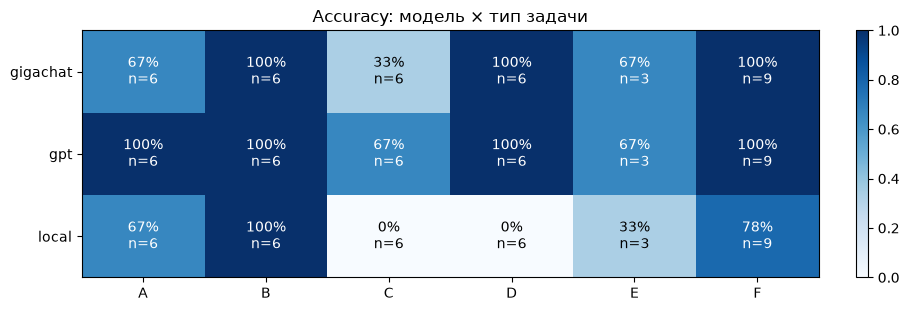

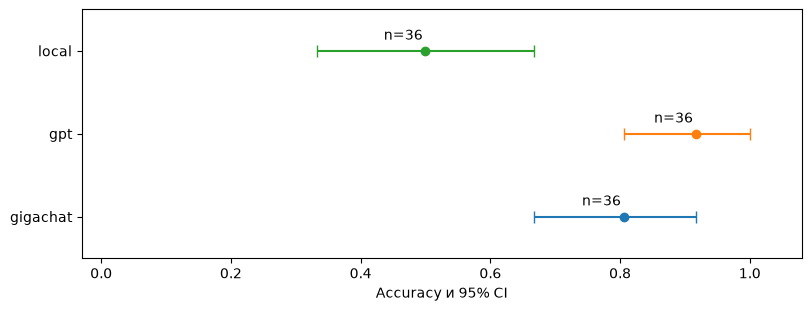

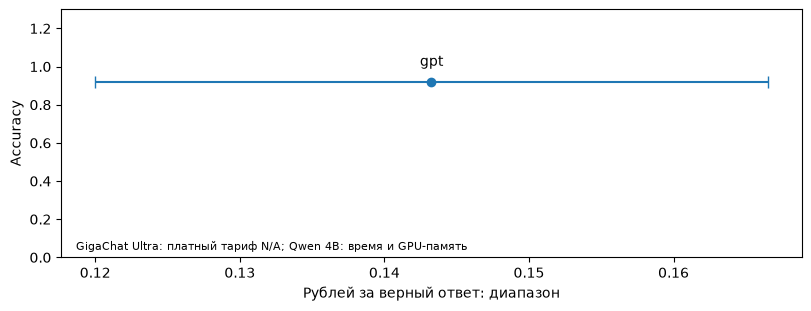

In [11]:
heat = by_type.pivot(index='model', columns='тип', values='mean').reindex(index=MODELS, columns=list('ABCDEF'))
counts = by_type.pivot(index='model', columns='тип', values='count').reindex(index=MODELS, columns=list('ABCDEF'))
fig, ax = plt.subplots(figsize=(9, 3), layout='constrained')
cmap = plt.colormaps['Blues'].copy(); cmap.set_bad('#eeeeee')
image = ax.imshow(np.ma.masked_invalid(heat.to_numpy()), cmap=cmap, vmin=0, vmax=1, aspect='auto')
ax.set(xticks=range(6), xticklabels=list('ABCDEF'), yticks=range(len(MODELS)), yticklabels=MODELS, title='Accuracy: модель × тип задачи')
for i, model in enumerate(MODELS):
    for j, kind in enumerate('ABCDEF'):
        value = heat.loc[model, kind]
        ax.text(j, i, f'{value:.0%}\nn={counts.loc[model, kind]}' if pd.notna(value) else '—', ha='center', va='center', color='white' if pd.notna(value) and value > 0.6 else 'black')
fig.colorbar(image, ax=ax); plt.show()
fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
for i, r in summary.iterrows():
    if pd.notna(r.accuracy):
        ax.errorbar(r.accuracy, i, xerr=[[max(0, r.accuracy-r.ci_low)], [max(0, r.ci_high-r.accuracy)]], fmt='o', capsize=4)
        ax.annotate(f'n={r.checked}', (r.accuracy, i), xytext=(-30, 8), textcoords='offset points')
ax.set(yticks=range(len(MODELS)), yticklabels=MODELS, xlim=(-0.03, 1.08), ylim=(-0.5, len(MODELS)-0.5), xlabel='Accuracy и 95% CI')
plt.show()
fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
for i, r in costs.dropna().iterrows():
    accuracy = summary.set_index('model').loc[r.model, 'accuracy']
    center = (r.rub_per_correct_low + r.rub_per_correct_high) / 2
    ax.errorbar(center, accuracy, xerr=(r.rub_per_correct_high-r.rub_per_correct_low)/2, fmt='o', capsize=4)
    ax.annotate(r.model, (center, accuracy), xytext=(0, 12+14*i), textcoords='offset points', ha='center')
ax.set(xlabel='Рублей за верный ответ: диапазон', ylabel='Accuracy', ylim=(0, 1.3))
ax.text(.02, .03, 'GigaChat Ultra: платный тариф N/A; Qwen 4B: время и GPU-память', transform=ax.transAxes, fontsize=8)
plt.show()

## Классификация E и H12
150 тестовых строк, непересекающиеся support 5/20; редкий класс — 0. Сравниваем F1 редкого класса и balanced accuracy с LogReg, GaussianNB и константным предсказанием. Полный дополнительный прогон пока есть только у GPT.

,model,shots,answered,planned
0,gpt,0,150,150
1,gpt,5,150,150
2,gpt,20,150,150


,model,shots,F1_rare,F1_low,F1_high,balanced_accuracy,BA_low,BA_high,accuracy
0,LogReg,5,0.8455284552845529,0.7716,0.9048,0.8845,0.8322,0.9290,0.8733
1,GaussianNB,5,0.7142857142857143,0.6293,0.7898,0.7623,0.7083,0.8118,0.7067
2,LogReg,20,0.9203539823008849,0.8571,0.9649,0.9377,0.8932,0.9747,0.9400
3,GaussianNB,20,0.8598130841121495,0.7812,0.9245,0.8841,0.8246,0.9373,0.9000
4,always_majority,20,0.0,0.0000,0.0000,0.5000,0.5000,0.5000,0.6267
5,gpt,0,0.8846153846153846,0.8119,0.9434,0.9001,0.8435,0.9493,0.9200
6,gpt,5,0.9369369369369369,0.8823,0.9800,0.9483,0.9063,0.9828,0.9533
7,gpt,20,0.9174311926605505,0.8571,0.9637,0.9305,0.8809,0.9679,0.9400


,model,shots,F1_delta_LogReg,ci_low,ci_high
0,gpt,5,0.0914,0.0403,0.1511
1,gpt,20,-0.0029,-0.0577,0.0452


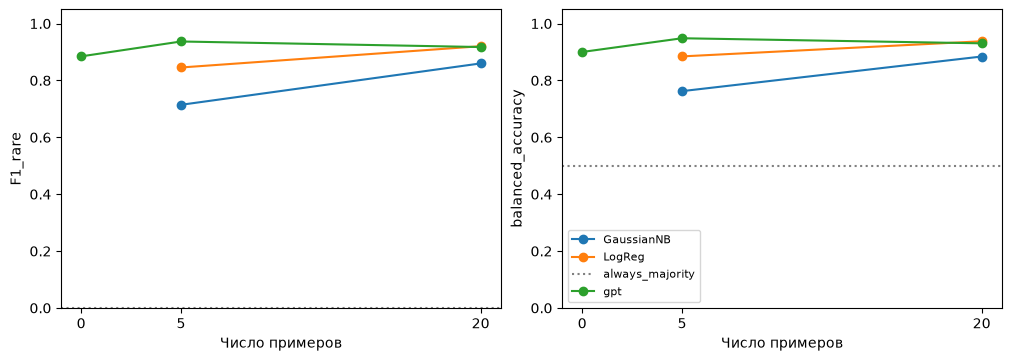

In [12]:
def metric(y, pred):
    rare = y == 0
    tp = np.sum(rare & (pred == 0), axis=-1)
    fp = np.sum(~rare & (pred == 0), axis=-1)
    fn = np.sum(rare & (pred != 0), axis=-1)
    f1 = np.divide(2*tp, 2*tp+fp+fn, out=np.zeros_like(tp, dtype=float), where=(2*tp+fp+fn)!=0)
    ba = .5*(np.sum(rare & (pred==0), axis=-1)/np.sum(rare, axis=-1)
              + np.sum(~rare & (pred==1), axis=-1)/np.sum(~rare, axis=-1))
    return f1, ba

records = read_records()
selected_extra = {}
for r in records:
    if r.get('stage') not in ['classification', 'hypotheses']:
        continue
    if r.get('answer') and not r.get('error') and r.get('finish_reason') != 'length':
        selected_extra.setdefault((r['model'], r['id']), r)
predictions = pd.DataFrame([{'model': r['model'], 'shots': r['shots'], 'row_id': int(r['row_id']),
                            'prediction': int(r['answer'].strip()) if r['answer'].strip() in ['0','1'] else -1}
                           for r in selected_extra.values() if r['stage'] == 'classification'])
y = test.target.to_numpy()
boot = np.random.default_rng(42).integers(0, len(test), (1000, len(test)))
baseline = {}
for shots in [5,20]:
    train = support.loc[support.in_5_shot.eq(1)] if shots == 5 else support
    for name, model in [('LogReg', make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))), ('GaussianNB', GaussianNB())]:
        baseline[(name, shots)] = model.fit(train[features], train.target).predict(test[features])
baseline[('always_majority',20)] = np.full(len(test), support.target.mode().iloc[0])
all_predictions = dict(baseline)
coverage = []
for (name, shots), group in predictions.groupby(['model','shots']):
    coverage.append({'model': name, 'shots': shots, 'answered': len(group), 'planned': len(test)})
    if len(group) == len(test) and not group.row_id.duplicated().any() and set(group.row_id) == set(test.row_id):
        all_predictions[(name,shots)] = test[['row_id']].merge(group,on='row_id').prediction.to_numpy()
metrics, h12 = [], []
for (name,shots), pred in all_predictions.items():
    f1, ba = metric(y,pred)
    sf, sb = metric(y[boot],pred[boot])
    fc, bc = np.quantile(sf,[.025,.975]), np.quantile(sb,[.025,.975])
    metrics.append({'model':name,'shots':shots,'F1_rare':f1,'F1_low':fc[0],'F1_high':fc[1],
                    'balanced_accuracy':ba,'BA_low':bc[0],'BA_high':bc[1], 'accuracy':np.mean(y==pred)})
    if name not in ['LogReg','GaussianNB','always_majority'] and shots in [5,20]:
        rf, rb = metric(y,baseline[('LogReg',shots)])
        bsf, bsb = metric(y[boot],baseline[('LogReg',shots)][boot])
        ci = np.quantile(sf-bsf,[.025,.975])
        h12.append({'model':name,'shots':shots,'F1_delta_LogReg':f1-rf,'ci_low':ci[0],'ci_high':ci[1]})
metrics, h12 = pd.DataFrame(metrics), pd.DataFrame(h12)
display(pd.DataFrame(coverage), metrics.round(4), h12.round(4))
fig, axes = plt.subplots(1,2,figsize=(10,3.5),layout='constrained')
for ax,column in zip(axes,['F1_rare','balanced_accuracy']):
    for name,group in metrics.groupby('model'):
        if name == 'always_majority': ax.axhline(group[column].iloc[0],color='gray',linestyle=':',label=name)
        else: ax.plot(group.shots,group[column],marker='o',label=name)
    ax.set(xlabel='Число примеров',ylabel=column,xticks=[0,5,20],ylim=(0,1.05))
axes[1].legend(fontsize=8)
plt.show()

## Гипотезы H3/H5/H12
Протокол новых задач зафиксирован [коммитом b39894f](https://github.com/SlavaLEVIN/bmstu-ml-lab3-llm/commit/b39894f) **после пилота**, до новых ответов. Это прогноз ассистента, не студенческая регистрация исходного эксперимента задним числом.

- **H3, группа 1:** выдуманный ответ при недостатке данных чаще корректного отказа. Прогноз: не подтвердится. Новые HF01–HF06; содержательную оценку отказов должен подтвердить человек.
- **H5, группа 2:** разрыв Qwen 4B с GigaChat/GPT больше на расчётных A, чем концептуальных B. Прогноз: подтвердится. Новые HA/HB по 6 задач; bootstrap разности разрывов, 1000 итераций, seed=42.
- **H12, группа 4:** при 5-shot LLM не хуже LogReg, при 20 — хуже. Прогноз: не подтвердится. Парный bootstrap одного test, 1000, seed=42; заранее не задан порог неухудшения.

Промпты контрольных задач и эталоны сохранены в `data/experiment.json`; эталоны модели не передаются.

,model,тип,mean,count
0,gpt,A,1.0,6
1,gpt,B,1.0,6
2,gpt,F,1.0,6


H5: не хватает дополнительных ответов GigaChat и Qwen.


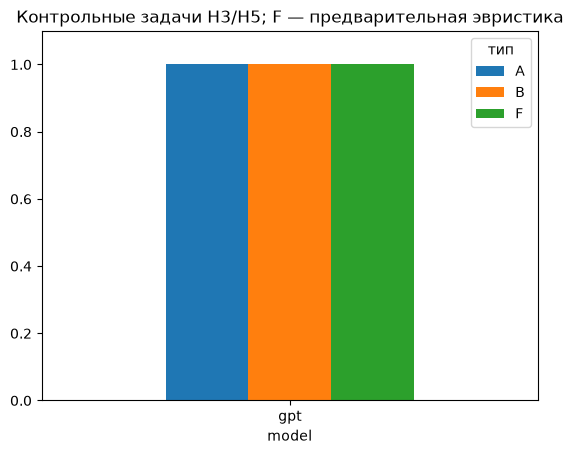

In [13]:
tasks = {r['id']: r for r in config['hypothesis_tasks']}
checks = []
for r in selected_extra.values():
    if r['stage'] != 'hypotheses': continue
    task, answer = tasks[r['id']], r['answer']
    tail = re.split(r'ответ\s*:', answer, flags=re.I)[-1].replace('{,}', '.')
    values = numbers(tail)
    if task['тип'] == 'A': correct = bool(values) and np.isclose(values[-1], float(task['gold']), rtol=.01)
    elif task['тип'] == 'B':
        match = re.search(r'\b(неверно|верно)\b', answer, re.I)
        correct = bool(match) and match[0].lower() == task['gold']
    else: correct = bool(re.search(r'нельзя|невозмож|недостат|не определ|неизвест|без.{0,50}(значени|дол|сведени)|не указ|не дан', answer, re.I))
    checks.append({'model':r['model'],'id':r['id'],'тип':task['тип'],'correct':int(correct),
                   'source':'heuristic_pending_human' if task['тип']=='F' else 'automatic'})
h = pd.DataFrame(checks)
h_scores = h.groupby(['model','тип']).correct.agg(['mean','count']).reset_index()
display(h_scores)
pair = h.loc[h['тип'].isin(['A','B'])].pivot(index='id',columns='model',values='correct')
if set(MODELS).issubset(pair.columns) and pair[MODELS].notna().all().all() and len(pair)==12:
    gap = pair[['gigachat','gpt']].mean(axis=1) - pair.local
    ga, gb = gap.loc[gap.index.str.startswith('HA')].to_numpy(), gap.loc[gap.index.str.startswith('HB')].to_numpy()
    rng = np.random.default_rng(42)
    delta = rng.choice(ga,(1000,6)).mean(axis=1) - rng.choice(gb,(1000,6)).mean(axis=1)
    print('H5: разность разрывов',ga.mean()-gb.mean(),'95% CI',np.quantile(delta,[.025,.975]))
else:
    print('H5: не хватает дополнительных ответов GigaChat и Qwen.')
h_scores.pivot(index='model',columns='тип',values='mean').plot.bar(ylim=(0,1.1),rot=0,title='Контрольные задачи H3/H5; F — предварительная эвристика')
plt.show()

## Ответы и разбор ошибок
CSV содержит одну запись на строку: переносы ответа представлены буквальными `\n`. Исходные тексты и программы сохранены в JSONL.

In [14]:
answers = df[['id','тип','model','текст_ru','answer','error','correct','score','assessment_source']].rename(
    columns={'текст_ru':'вопрос','answer':'ответ','error':'ошибка','correct':'верно','score':'балл','assessment_source':'источник_оценки'})
save(answers, Path('answers.csv'))
wrong = df.loc[df.correct.eq(0) | df.score.lt(2) | df.method_error.eq(1)]
print(f'Ответов: {df.received.sum()} / {len(df)}; оценено: {df.correct.notna().sum()}; предварительно ИИ: {df.assessment_source.eq("ai_preliminary").sum()}.')
print('Итоговая таблица: answers.csv')
display(wrong[['id','model','тип','correct','score']])

Ответов: 108 / 108; оценено: 108; предварительно ИИ: 63.
Итоговая таблица: answers.csv


,id,model,тип,correct,score
3,A02,gigachat,A,0.0,NaN
5,A02,local,A,0.0,NaN
9,A04,gigachat,A,0.0,NaN
11,A04,local,A,0.0,NaN
20,B01,local,B,1.0,1.0
36,C01,gigachat,C,0.0,1.0
37,C01,gpt,C,0.0,1.0
38,C01,local,C,0.0,1.0
41,C02,local,C,0.0,1.0
42,C03,gigachat,C,0.0,1.0


### Пять показательных ошибок
1. **GigaChat A04:** «0.5625*0.4/(0.5625*0.4+1/18*0.6)=0.9». Формула верна, арифметика нет: результат **0.8709677**.
2. **Qwen A02:** «0.32 - [0.071 + 0.119] = … = 0.13». Неточные промежуточные вычисления дают ошибочный прирост Джини вместо **0.1212474**.
3. **Qwen B01:** метка «верно», но объяснение «Увеличение C … уменьшает штраф». Штраф **увеличивается**; рубрика 1/2, хотя метка правильная.
4. **Qwen D02:** `pipeline = Pipeline(...)` при отсутствии импорта `Pipeline`: **NameError**, pass@1=0. Импорт перед оценкой не исправлялся.
5. **Qwen F07:** «порог не определяется». Условие достаточно: 10(1−p) ≤ 90p, поэтому порог **0.1**. Это ошибочный отказ.

### Доступные итоги и ограничения
У GPT при 5-shot ΔF1 с LogReg **+0.0914**, CI [0.0403; 0.1511]; при 20-shot **−0.0029**, CI [−0.0577; 0.0452]. Для второй части H12 данных недостаточно; включение нуля не доказывает эквивалентность. Для H3 у GPT предварительно 6/6 корректных указаний недостатка данных; нужна содержательная проверка человеком. H5 ждёт ответов других моделей на новые задачи.

- C/D/F оценены предварительно ИИ; два независимых человека и каппа ещё нужны.
- 36 задач мало для обобщения на все задачи ML; гипотезы выбраны после пилота, авторство части задач и заимствованные источники требуют подтверждения.
- По PDF требуются **четыре модели, две российские**; фактически есть три. Не полученные результаты не включены.
- GPT используется через посредника LLM Gate; справочный тариф не равен выписке провайдера. Часть старого usage неполна. Новые параллельные GPT-вызовы не смешиваются с последовательными задержками пилота.

| Тип | Предварительная рекомендация | Проверка |
|---|---|---|
| A | Проверять каждый ответ | вычислить число независимо |
| B | Проверять выборочно | смотреть и метку, и обоснование |
| C | Проверять по рубрике | условия и необходимые шаги |
| D | Проверять каждый ответ | запустить неизменённый код, проверить методологию |
| E | Проверять на отдельном test | F1 редкого класса, BA и baseline |
| F | Проверять каждый ответ | достаточно ли данных и обоснован ли отказ |

Окончательные выводы отчёта по заданию пишут авторы работы.

<details><summary>Подготовка к защите: 12 коротких ответов</summary>

1. 34/40 против 31/40 ещё не доказывает превосходство. При трёх расхождениях только в пользу A точный двусторонний Макнемар даёт p=0.25.
2. Известная задача могла быть в обучении; нужны новые числа и условия на заранее фиксированном тесте.
3. LLM-судья может иметь общие ошибки с моделью и предпочитать знакомый стиль; это не независимая проверка людьми.
4. Температура 0 не фиксирует серверную версию и вычисления GPU; нужны версии, параметры, журналы и повторы.
5. Accuracy 96.5% может совпадать с частым классом; нужны F1 редкого класса и balanced accuracy.
6. Цена за токен не учитывает длину ответа, токенизацию русского, скрытые рассуждения и долю верных решений.
7. Постоянная уверенность 0.9 при accuracy 0.9 может дать ECE=0, но не помогает отличить рискованные ответы.
8. Support и test могут пересечься; оба класса должны присутствовать в support, преобразования обучаются только на нём.
9. 32 верных и 8 отказов: общая accuracy=0.8, selective accuracy=1 при coverage=0.8; правильный отказ при недостатке данных засчитывается верным.
10. Настройка промпта по тестовым ответам GigaChat — аналог переобучения; нужен отдельный dev-набор и замороженный промпт.
11. Разные правильные тексты сохраняют устойчивость правильности. Два неверных ответа тоже совпадают по правильности, но accuracy=0.
12. SVM w=(3,4), b=−2, x=(1,0): класс +1, полная ширина зазора 0.4, расстояние 0.2; точка лежит на положительной границе зазора. Без обучающей выборки нельзя утверждать, что это её опорный вектор.

Доклад на 5 минут: цель/гипотезы → модели/банк/проверка → accuracy/CI/Макнемар → E/baselines → ошибки/ограничения/собственные выводы.
</details>